# 2. Modelos y entrenamiento
Se comparan cuatro modelos con **el mismo protocolo** (bloques de 12 m × 12 m, entrenamiento: Áreas 1 y 3–7, validación: Área 8, prueba: Área 2):

| Modelo | Script |
|---|---|
| PointNet++ (SSG) | `code/train.py` |
| PTv3 desde cero | `code/train_ptv3.py --model ptv3` |
| PTv3 + Sonata (preentrenado) | `code/train_ptv3.py --model sonata_small` |
| PTv3 + Utonia (preentrenado) | `code/train_ptv3.py --model utonia_tiny` |

Cada entrenamiento tarda entre 45 min y 2 h en una RTX 4060 Ti; por eso se ejecutaron con `code/run_all.sh` y aquí se cargan sus registros. Para reentrenar, cambie `ENTRENAR = True`.

In [1]:
import json, sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent            # carpeta raíz del proyecto
sys.path.insert(0, str(ROOT / "code"))
DATA, RAW, RUNS = ROOT / "data" / "processed", ROOT / "data" / "3DAeroRelief", ROOT / "runs"
CLASES = ["Fondo", "Edif. dañada", "Edif. sin daño", "Vía", "Árbol"]
pd.set_option("display.precision", 3)
print("Proyecto:", ROOT.name)

Proyecto: Proyecto_Electiva_Danos_Estructurales


## 2.1 Arquitecturas y número de parámetros

In [2]:
import torch
from pointnet2 import PointNet2Seg
from train_ptv3 import Segmentor
filas = [dict(Modelo="PointNet++", Parámetros=sum(p.numel() for p in PointNet2Seg(7, 5).parameters()))]
for nombre, preset in [("PTv3 desde cero", "ptv3"), ("PTv3 + Sonata", "sonata_small"), ("PTv3 + Utonia", "utonia_tiny")]:
    m = Segmentor(preset, 5)
    filas.append(dict(Modelo=nombre, Parámetros=sum(p.numel() for p in m.parameters())))
t = pd.DataFrame(filas); t["Millones"] = (t["Parámetros"] / 1e6).round(1); t

,Modelo,Parámetros,Millones
0,PointNet++,964229,1.0
1,PTv3 desde cero,46196709,46.2
2,PTv3 + Sonata,38904965,38.9
3,PTv3 + Utonia,9452557,9.5


## 2.2 Comandos de entrenamiento (3 semillas por modelo, según presupuesto)

In [3]:
ENTRENAR = False
cmd_pn2 = "python train.py --data ../data/processed --out ../runs/{run} --block 12 --epochs 40 --iters 400 --bs 16 --val_every 4 --seed {seed}"
cmd_ptv3 = "python train_ptv3.py --data ../data/processed --out ../runs/{run} --model {model} --seed {seed} --epochs 30 --iters 400 --bs 4 --val_every 3"
plan = [("pn2", None, 0), ("pn2_s1", None, 1), ("pn2_s2", None, 2), ("ptv3_s0", "ptv3", 0)] + \
       [(f"sonata_s{s}", "sonata_small", s) for s in range(3)] + [(f"utonia_tiny_s{s}", "utonia_tiny", s) for s in range(3)]
for run, model, seed in plan:
    c = cmd_pn2.format(run=run, seed=seed) if model is None else cmd_ptv3.format(run=run, model=model, seed=seed)
    print(c)
    if ENTRENAR:
        import subprocess
        subprocess.run([sys.executable] + c.split()[1:], cwd=ROOT / "code", check=True)

python train.py --data ../data/processed --out ../runs/pn2 --block 12 --epochs 40 --iters 400 --bs 16 --val_every 4 --seed 0
python train.py --data ../data/processed --out ../runs/pn2_s1 --block 12 --epochs 40 --iters 400 --bs 16 --val_every 4 --seed 1
python train.py --data ../data/processed --out ../runs/pn2_s2 --block 12 --epochs 40 --iters 400 --bs 16 --val_every 4 --seed 2
python train_ptv3.py --data ../data/processed --out ../runs/ptv3_s0 --model ptv3 --seed 0 --epochs 30 --iters 400 --bs 4 --val_every 3
python train_ptv3.py --data ../data/processed --out ../runs/sonata_s0 --model sonata_small --seed 0 --epochs 30 --iters 400 --bs 4 --val_every 3
python train_ptv3.py --data ../data/processed --out ../runs/sonata_s1 --model sonata_small --seed 1 --epochs 30 --iters 400 --bs 4 --val_every 3
python train_ptv3.py --data ../data/processed --out ../runs/sonata_s2 --model sonata_small --seed 2 --epochs 30 --iters 400 --bs 4 --val_every 3
python train_ptv3.py --data ../data/processed --o

## 2.3 Registros de entrenamiento: mejor mIoU de validación y tiempo

In [4]:
NOMBRE = {"pn2": "PointNet++", "ptv3": "PTv3 desde cero", "sonata": "PTv3 + Sonata", "utonia": "PTv3 + Utonia"}
filas = []
for run, _, seed in plan:
    r = json.loads((RUNS / run / "results.json").read_text())
    log = json.loads((RUNS / run / "log.json").read_text())
    mejor = max((e for e in log if "val_mIoU" in e), key=lambda e: e["val_mIoU"])
    filas.append(dict(Corrida=run, Modelo=NOMBRE[run.split("_")[0]], Semilla=seed, Épocas=len(log),
                      **{"Mejor mIoU val.": r["best_val_mIoU"], "Época del mejor": mejor["epoch"],
                         "Tiempo (min)": round(r["train_time_min"])}))
pd.DataFrame(filas)

,Corrida,Modelo,Semilla,Épocas,Mejor mIoU val.,Época del mejor,Tiempo (min)
0,pn2,PointNet++,0,40,0.539,20,124
1,pn2_s1,PointNet++,1,40,0.532,12,160
2,pn2_s2,PointNet++,2,40,0.516,16,97
3,ptv3_s0,PTv3 desde cero,0,30,0.530,30,46
4,sonata_s0,PTv3 + Sonata,0,30,0.552,9,30
5,sonata_s1,PTv3 + Sonata,1,30,0.553,9,37
6,sonata_s2,PTv3 + Sonata,2,30,0.552,12,30
7,utonia_tiny_s0,PTv3 + Utonia,0,30,0.532,9,52
8,utonia_tiny_s1,PTv3 + Utonia,1,30,0.554,3,81
9,utonia_tiny_s2,PTv3 + Utonia,2,30,0.578,6,59


## 2.4 Curvas de entrenamiento (mIoU de validación, Área 8)

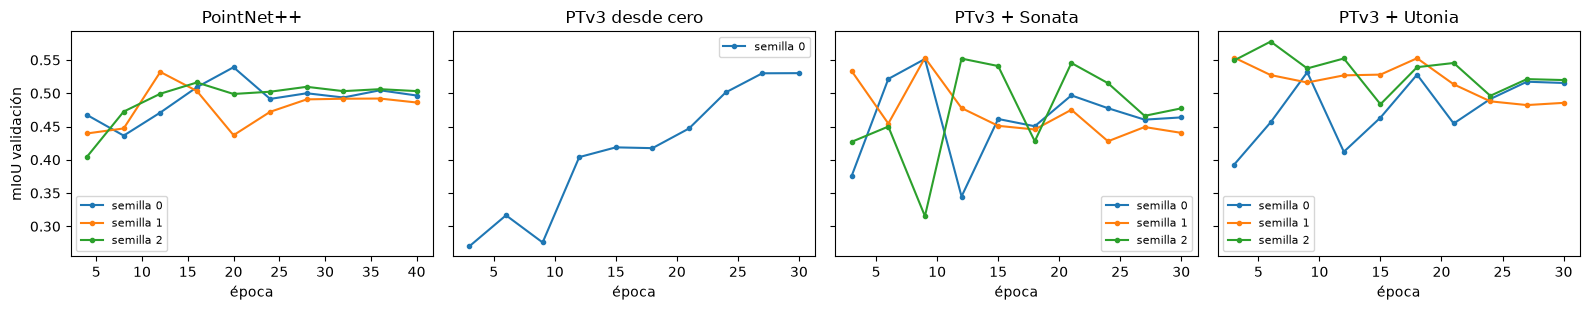

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for i, pref in enumerate(["pn2", "ptv3", "sonata", "utonia"]):
    for run, _, seed in plan:
        if run.split("_")[0] != pref:
            continue
        log = json.loads((RUNS / run / "log.json").read_text())
        v = [(e["epoch"], e["val_mIoU"]) for e in log if "val_mIoU" in e]
        ax[i].plot(*zip(*v), "o-", ms=3, label=f"semilla {seed}")
    ax[i].set_title(NOMBRE[pref]); ax[i].set_xlabel("época"); ax[i].legend(fontsize=8)
ax[0].set_ylabel("mIoU validación"); plt.tight_layout(); plt.show()

Los modelos preentrenados alcanzan su mejor validación en pocas épocas y luego se sobreajustan; PTv3 desde cero aprende más despacio. Por eso se guarda el checkpoint con mejor mIoU de validación (`best.pt`).